In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import confusion_matrix
import seaborn as sns
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error

In [2]:
def run_mlr(lag):
    #Loading in Data
    df = pd.read_csv('/Users/timothyconsidine/Desktop/School/Spring 2026/Machine Learning/Project/PRSA_data_2010.1.1-2014.12.31.csv')

    #Converting time variables into one datetime variable
    df['datetime'] = pd.to_datetime(df[['year', 'month', 'day', 'hour']])
    df = df.set_index('datetime')

    # Drop the original time columns and the 'No' index column
    df = df.drop(columns=['No', 'year', 'month', 'day', 'hour'])

    #Filling in missing values
    df['pm2.5'] = df['pm2.5'].ffill().bfill()

    #Creating dummy variables for wind direction features
    df = pd.get_dummies(df, columns=['cbwd'], drop_first=True)

    #Adding lag features
    if lag == 0:
        df['pm2.5_lag_24hr'] = df['pm2.5'].shift(24)
    else:
        df['pm2.5_lag_24hr'] = df['pm2.5'].shift(24)
        df[f'pm2.5_lag_{lag}hr'] = df['pm2.5'].shift(lag)

    # Drop the first 24 rows since they will have missing values from the shift
    df = df.dropna()

    #Splitting the data into training and testing data
    train = df[df.index < '2014-01-01']
    test = df[df.index >= '2014-01-01']

    X_train = train.drop(columns=['pm2.5'])
    y_train = train['pm2.5']
    X_test = test.drop(columns=['pm2.5'])
    y_test = test['pm2.5']

    model = LinearRegression()

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)

    return mae

In [3]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import matplotlib.pyplot as plt

def run_rf(lag):
    # ==========================================
    # 1. Load and Clean the Data
    # ==========================================
    # Load the dataset
    df = pd.read_csv('/Users/timothyconsidine/Desktop/School/Spring 2026/Machine Learning/Project/PRSA_data_2010.1.1-2014.12.31.csv')

    # Combine year, month, day, and hour into a proper datetime index
    df['datetime'] = pd.to_datetime(df[['year', 'month', 'day', 'hour']])
    df = df.set_index('datetime')

    # Drop the original time columns and the 'No' index column
    df = df.drop(columns=['No', 'year', 'month', 'day', 'hour'])

    # Handle missing PM2.5 values using forward fill, then backward fill 
    # (Air quality changes gradually, so the previous hour's value is a safe estimate)
    df['pm2.5'] = df['pm2.5'].ffill().bfill()

    # One-hot encode the categorical wind direction ('cbwd')
    df = pd.get_dummies(df, columns=['cbwd'], drop_first=True, dtype=float)

    # ==========================================
    # 2. Feature Engineering (Lag Features)
    # ==========================================
    # We want to predict current PM2.5 using past PM2.5 values.
    if lag == 0:
        df['pm2.5_lag_24hr'] = df['pm2.5'].shift(24)
    else:
        df[f'pm2.5_lag_{lag}hr'] = df['pm2.5'].shift(lag)   
        df['pm2.5_lag_24hr'] = df['pm2.5'].shift(24) 

    # Drop the first 24 rows since they will have missing values from the shift
    df = df.dropna()

    # ==========================================
    # 3. Chronological Train-Test Split
    # ==========================================
    # Train on 2010-2013, Test on 2014 to avoid data leakage
    train = df[df.index < '2014-01-01']
    test = df[df.index >= '2014-01-01']

    # Separate features (X) and target (y)
    X_train = train.drop(columns=['pm2.5'])
    y_train = train['pm2.5']
    X_test = test.drop(columns=['pm2.5'])
    y_test = test['pm2.5']
    ######################################################################<HERE
    # ==========================================
    # 4. Model Training
    # ==========================================
    # Initialize and train the Random Forest
    # n_jobs=-1 uses all available CPU cores to speed up training
    rf_model = RandomForestRegressor(n_estimators=100, max_features=0.3,random_state=42, n_jobs=-1)
    rf_model.fit(X_train, y_train)

    # ==========================================
    # 5. Evaluation and Metrics
    # ==========================================
    # Generate predictions on the 2014 test set
    predictions = rf_model.predict(X_test)

    # Calculate metrics
    mae = mean_absolute_error(y_test, predictions)
    
    return mae


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error

def run_gb(lag):
    # 1. Load and Preprocess the Data
    df = pd.read_csv('/Users/timothyconsidine/Desktop/School/Spring 2026/Machine Learning/Project/PRSA_data_2010.1.1-2014.12.31.csv')

    # Combine time columns into a datetime index
    df['datetime'] = pd.to_datetime(df[['year', 'month', 'day', 'hour']])
    df = df.set_index('datetime')

    # Clean PM2.5 and encode wind direction
    df['pm2.5'] = df['pm2.5'].ffill().bfill()
    df = pd.get_dummies(df, columns=['cbwd'], drop_first=True, dtype=float)

    # 2. Feature Engineering: 24-Hour Lag
    # Captures the "baseline" of pollution from this time yesterday
    if lag == 0:
        df['pm2.5_lag_24hr'] = df['pm2.5'].shift(24)
    else:
        df[f'pm2.5_lag_{lag}hr'] = df['pm2.5'].shift(lag)   
        df['pm2.5_lag_24hr'] = df['pm2.5'].shift(24) 
        
    df = df.dropna()

    # 3. Chronological Train-Test Split
    # Training: 2010-2013 (First four years to maximize learning)
    # Testing: 2014 (The final year)
    train = df[df.index < '2014-01-01']
    test = df[df.index >= '2014-01-01']

    features_to_drop = ['No', 'pm2.5', 'year', 'month', 'day', 'hour']
    X_train = train.drop(columns=features_to_drop)
    y_train = train['pm2.5']
    X_test = test.drop(columns=features_to_drop)
    y_test = test['pm2.5']

    # 4. Hyperparameter Search Setup
    # We explore different combinations of learning rates and complexity
    param_distributions = {
        'n_estimators': [100, 300, 500],
        'learning_rate': [0.01, 0.05, 0.1],
        'max_depth': [3, 5, 8],
        'subsample': [0.8, 1.0],           # Stochastic gradient boosting (helps prevent overfitting)
        'min_samples_split': [2, 5, 10]
    }

    # Preserve chronological order in cross-validation
    tscv = TimeSeriesSplit(n_splits=3)

    # Initialize base model
    gbt_base = GradientBoostingRegressor(random_state=42)

    # Set up the Search wrapper
    random_search = RandomizedSearchCV(
        estimator=gbt_base,
        param_distributions=param_distributions,
        n_iter=15,                         # Tests 15 random combinations
        cv=tscv,
        scoring='neg_mean_squared_error',
        verbose=1,
        n_jobs=-1,
        random_state=42
    )

    # 5. Run Search and Select Best Model
    print("Starting Hyperparameter Search...")
    random_search.fit(X_train, y_train)

    # Extract the winning model
    best_gbt = random_search.best_estimator_
    print(f"\nBest Parameters Found: {random_search.best_params_}")

    # 6. Evaluation and Metrics
    y_pred = best_gbt.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)
    #rmse = np.sqrt(mean_squared_error(y_test, y_pred))

    return mae 

In [5]:
lags = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 0]

mlr = []
rf = []
gb = []

for lag in lags:
    mae1 = run_mlr(lag)
    mae2 = run_rf(lag)
    mae3 = run_gb(lag)
    mlr.append(mae1)
    rf.append(mae2)
    gb.append(mae3)

lags.remove(0)
lags.append(24)
lags

Starting Hyperparameter Search...
Fitting 3 folds for each of 15 candidates, totalling 45 fits

Best Parameters Found: {'subsample': 1.0, 'n_estimators': 100, 'min_samples_split': 2, 'max_depth': 3, 'learning_rate': 0.1}
Starting Hyperparameter Search...
Fitting 3 folds for each of 15 candidates, totalling 45 fits

Best Parameters Found: {'subsample': 1.0, 'n_estimators': 100, 'min_samples_split': 2, 'max_depth': 3, 'learning_rate': 0.1}
Starting Hyperparameter Search...
Fitting 3 folds for each of 15 candidates, totalling 45 fits

Best Parameters Found: {'subsample': 1.0, 'n_estimators': 100, 'min_samples_split': 2, 'max_depth': 3, 'learning_rate': 0.1}
Starting Hyperparameter Search...
Fitting 3 folds for each of 15 candidates, totalling 45 fits

Best Parameters Found: {'subsample': 1.0, 'n_estimators': 100, 'min_samples_split': 2, 'max_depth': 3, 'learning_rate': 0.1}
Starting Hyperparameter Search...
Fitting 3 folds for each of 15 candidates, totalling 45 fits

Best Parameters Foun

[1,
 2,
 3,
 4,
 5,
 6,
 7,
 8,
 9,
 10,
 11,
 12,
 13,
 14,
 15,
 16,
 17,
 18,
 19,
 20,
 21,
 22,
 23,
 24]

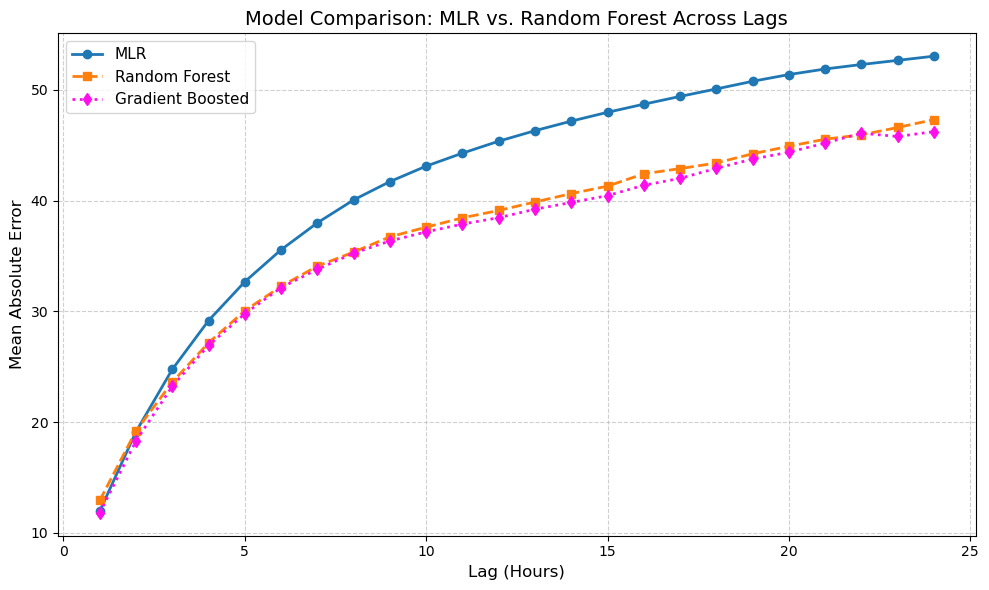

In [7]:
plt.figure(figsize=(10, 6))

# Plot the MLR line
# marker='o' adds dots to the data points, making them easier to read
plt.plot(lags, mlr, label='MLR', color='#1f77b4', marker='o', linewidth=2)

# Plot the Random Forest line
# linestyle='--' makes it a dashed line, which helps distinguish it from MLR
plt.plot(lags, rf, label='Random Forest', color='#ff7f0e', marker='s', linewidth=2, linestyle='--')

#Plot the Gradient Boost Line
plt.plot(lags, gb, label='Gradient Boosted', color="#ff0eeb", marker='d', linewidth=2, linestyle='dotted')

# ==========================================
# 3. Format and Customize
# ==========================================
plt.title('Model Comparison: MLR vs. Random Forest Across Lags', fontsize=14)
plt.xlabel('Lag (Hours)', fontsize=12)
plt.ylabel('Mean Absolute Error', fontsize=12)

# Add a legend to show which line is which
plt.legend(fontsize=11)

# Add a grid for readability
plt.grid(True, linestyle='--', alpha=0.6)

# Ensure everything fits perfectly
plt.tight_layout()

plt.savefig('/Users/timothyconsidine/Desktop/School/Spring 2026/Machine Learning/Project/lags')

